<a href="https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/07-segmentacion-de-clientes/clase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Episodio 2.7 · Segmentación de clientes

**Serie:** Del Excel al Machine Learning · **Temporada 2** · 🎬 Video próximamente

## 🎯 Qué vas a aprender

- Qué es **agrupar sin una respuesta correcta**.
- Usar **k-means** y por qué hay que **escalar** las columnas.
- Por qué los grupos son **una decisión**, no un descubrimiento.

## 📊 En Excel lo harías así

Armas una tabla dinámica de clientes y pones rangos a mano: *"chicos, medianos, grandes"*. ¿Dónde cortas? Lo decides tú, mirando una sola columna.

**k-means** hace algo parecido con varias columnas a la vez. Es distinto a todo lo que hemos visto: aquí **no hay un objetivo que predecir**.

## 🐍 En Python

### Paso 1: una fila por cliente

Resumimos a cada cliente en tres números: días sin comprar, pedidos por mes y compra por mes. Los meses se cuentan desde su primera compra hasta la última, para no castigar a los clientes nuevos.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

DATOS = "https://raw.githubusercontent.com/PercyTechX/del-excel-al-ml/main/datos/"

In [2]:
def resumen_de_clientes(ventas):
    """Una fila por cliente: días sin comprar, y pedidos y compra por mes activo."""
    fecha = pd.to_datetime(ventas["fecha"])
    tabla = (
        ventas.assign(fecha=fecha)
        .groupby("id_cliente")
        .agg(
            primera=("fecha", "min"),
            ultima=("fecha", "max"),
            pedidos=("fecha", "nunique"),
            total=("total", "sum"),
        )
    )
    meses = ((tabla["ultima"] - tabla["primera"]).dt.days / 30.44).clip(lower=1)
    return pd.DataFrame(
        {
            "dias_sin_comprar": (pd.Timestamp("2025-12-31") - tabla["ultima"]).dt.days,
            "pedidos_mes": (tabla["pedidos"] / meses).round(1),
            "compra_mes": (tabla["total"] / meses).round(1),
        }
    )

In [3]:
ventas = pd.read_csv(DATOS + "ventas.csv")
clientes = pd.read_csv(DATOS + "clientes.csv").set_index("id_cliente")

resumen = resumen_de_clientes(ventas)

print(len(resumen))

resumen.head()

300


,dias_sin_comprar,pedidos_mes,compra_mes
id_cliente,,,
C0001,4,3.4,578.2
C0002,0,11.3,5334.3
C0003,0,4.5,851.2
C0004,2,3.8,841.9
C0005,2,6.2,1940.3


### Paso 2: k-means, sin escalar

Le pedimos 4 grupos con `n_clusters=4`. El 4 lo elegimos nosotros. k-means coloca 4 centros y reparte a cada cliente en el más cercano.

Primero lo hacemos mal a propósito:

In [4]:
sin_escalar = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(resumen)

resumen.groupby(sin_escalar).mean().round(1).assign(clientes=resumen.groupby(sin_escalar).size())

,dias_sin_comprar,pedidos_mes,compra_mes,clientes
0,45.7,6.9,2076.8,120
1,120.5,15.1,8072.9,13
2,32.1,10.5,4166.2,41
3,29.1,4.0,904.0,126


Los grupos se ordenan por la compra mensual, y los clientes que dejaron de comprar quedan repartidos. ¿Por qué? **k-means mide distancias.** Una diferencia de S/ 1,000 pesa mil veces más que 1 pedido, solo porque está en otra unidad.

### Paso 3: escalar

`StandardScaler` deja cada columna en una escala comparable. Lo usamos en el 1.7.

In [5]:
escalados = StandardScaler().fit_transform(resumen)

grupos = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(escalados)

resumen.groupby(grupos).mean().round(1).assign(clientes=resumen.groupby(grupos).size())

,dias_sin_comprar,pedidos_mes,compra_mes,clientes
0,5.9,4.7,1218.7,181
1,42.8,15.2,8088.3,12
2,392.6,6.8,2267.7,25
3,8.0,9.4,3226.1,82


Ahora sí aparece un grupo de 25 clientes que llevan, en promedio, unos 13 meses sin comprar, y el que menos, 7. Los demás se ordenan por tamaño.

Fíjate en cómo cambió el resultado con una línea. **No hay una respuesta correcta que nos avise.** Por eso hay que mirar siempre qué salió.

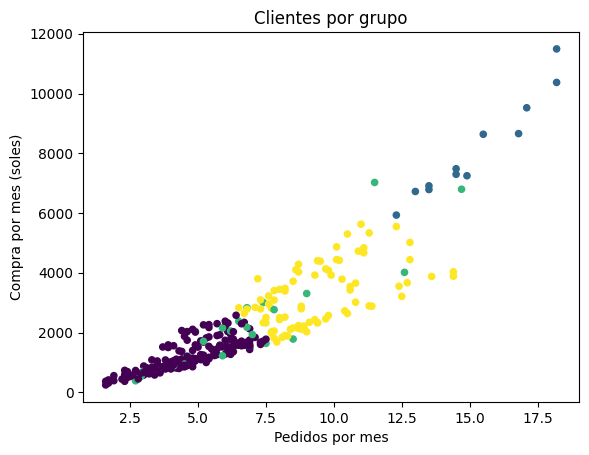

In [6]:
plt.scatter(resumen["pedidos_mes"], resumen["compra_mes"], c=grupos, cmap="viridis", s=20)
plt.title("Clientes por grupo")
plt.xlabel("Pedidos por mes")
plt.ylabel("Compra por mes (soles)")
plt.show()

Cada color es un grupo. Los perdidos se ven mezclados porque este gráfico no muestra los días sin comprar: no es que k-means haya fallado.

### Paso 4: ¿qué significa cada grupo?

¿Ya lo sabíamos por el tipo de cliente? Una tabla dinámica lo responde:

In [7]:
pd.crosstab(grupos, clientes["tipo"].reindex(resumen.index))

tipo,Bodega,Minimarket,Restaurante
row_0,,,
0,134,20,27
1,0,12,0
2,12,9,4
3,34,34,14


Se parecen a `tipo`, pero no son lo mismo. Hay minimarkets en varios grupos, y una bodega también puede parecerse a un negocio más grande.

Mira además a este cliente:

In [8]:
resumen.assign(grupo=grupos).loc["C0105"]

dias_sin_comprar     508.0
pedidos_mes           16.8
compra_mes          8658.6
grupo                  1.0
Name: C0105, dtype: float64

Lleva más de 500 días sin comprar, y compraba más de S/ 8,000 al mes. Pero cayó en el grupo de los grandes, porque se parece a ellos en las otras dos columnas. **Un gran cliente perdido, escondido en el promedio.** Una regla de Excel lo encuentra enseguida, como en el ejercicio del 1.9: los grupos no reemplazan a las reglas. Con otros datos, puede que no aparezca un caso así.

### ¿Y por qué 4?

Porque lo elegimos. Con 3 o 5 también saldrían grupos. No hay un número "real" de grupos en estos datos. La prueba es práctica: **¿qué haría la empresa distinto con cada grupo?** Si dos grupos reciben el mismo trato, sobra uno.

> ⚠️ **Datos sintéticos.** Con otros datos, estos grupos cambian.

## 🤖 Pídeselo a la IA

> *"Tengo clientes agrupados en: grandes, medianos, chicos y perdidos. Propón una acción comercial concreta para cada grupo, y dime cómo mediría si funcionó."*

La IA te ayuda a escribir y entender código, pero **tú debes entender lo que hace**. Revisa cada respuesta antes de usarla, y no pegues datos de tu empresa.

## ✅ Resumen

| En Excel | En Python |
|---|---|
| Rangos a mano | `KMeans(n_clusters=4, n_init=10, random_state=0)` |
| Poner las columnas en la misma escala | `StandardScaler().fit_transform(tabla)` |
| Tabla dinámica por grupo | `tabla.groupby(grupos).mean()` |
| Cruzar con otra columna | `pd.crosstab(grupos, columna)` |

## 📝 Ahora te toca

Abre [el ejercicio en Colab](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/07-segmentacion-de-clientes/ejercicio.ipynb) y arma tus propios grupos. Cuando termines, compara con [la solución](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/07-segmentacion-de-clientes/solucion.ipynb).

---

*Del Excel al Machine Learning* · por [Percy Nazario](https://www.linkedin.com/in/percy-nazario/) · [Repositorio](https://github.com/PercyTechX/del-excel-al-ml) · Contenido bajo licencia CC BY 4.0